# Medical Insurance Charges Prediction
Predict `charges` from demographic and lifestyle features using **Linear Regression** and **Polynomial Regression**. Dataset: Kaggle `mirichoi0218/insurance`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the dataset
Download the insurance dataset with `kagglehub` and read it into a DataFrame.

In [ ]:
!pip install -q kagglehub

import kagglehub
import pandas as pd

path = kagglehub.dataset_download("mirichoi0218/insurance")
df = pd.read_csv(path + "/insurance.csv")
df.head()

Using Colab cache for faster access to the 'insurance' dataset.


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Initial inspection and cleaning
Check shape, dtypes, missing values (none) and duplicates (1 found and removed).

In [ ]:
df.shape

(1338, 7)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.isna().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df = df.drop_duplicates()

## 3. Feature encoding
One-hot encode `sex`, `smoker` and `region` (`drop_first=True`).

In [ ]:
df_enc = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True, dtype=int)
df_enc.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


## 4. Features, target and train/test split
Target: `charges`. 80/20 split with `random_state=42` (1,069 train / 268 test).

In [ ]:
X = df_enc.drop("charges", axis=1)
y = df_enc["charges"]

print(X.shape, y.shape)

(1337, 8) (1337,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (1069, 8)
X_test : (268, 8)


## 5. Feature scaling
`StandardScaler` is fitted on the training set only, then applied to the test set.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)         

## 6. Linear Regression (baseline)
Test results: R² = 0.8069, RMSE = 5,956.34, MAE = 4,177.05.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)

y_pred_lin = lin_model.predict(X_test_scaled)

mse_lin = mean_squared_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
mae_lin = mean_absolute_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)

print(f"MSE : {mse_lin:.2f}")
print(f"RMSE: {rmse_lin:.2f}")
print(f"MAE : {mae_lin:.2f}")
print(f"R2  : {r2_lin:.4f}")

MSE : 35478020.68
RMSE: 5956.34
MAE : 4177.05
R2  : 0.8069


In [ ]:
print("Intercept:", lin_model.intercept_)

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lin_model.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

print(coef_df)

Intercept: 13030.203369289053
            Feature  Coefficient
4        smoker_yes  9234.342487
0               age  3472.975553
1               bmi  1927.828251
2          children   636.501185
6  region_southeast  -371.780810
7  region_southwest  -284.610396
5  region_northwest  -168.944439
3          sex_male   -50.749675


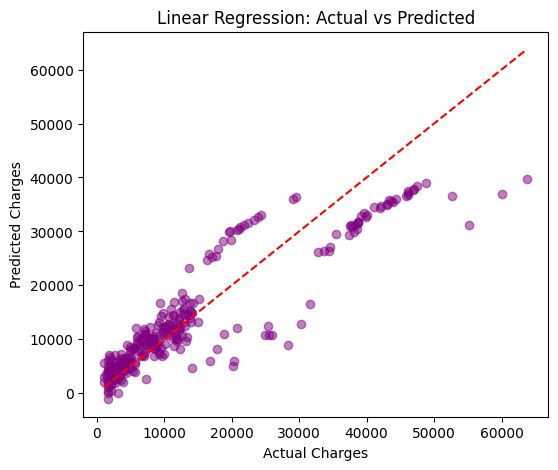

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_lin, alpha=0.5, color="purple")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

## 7. Polynomial Regression
Compare degrees 1–4, then fit degree 2 (test R² = 0.8825, RMSE = 4,646.06, MAE = 2,867.32).

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

results = []

for d in [1, 2, 3, 4]:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_r2 = r2_score(y_train, model.predict(X_train_poly))
    test_pred = model.predict(X_test_poly)
    test_r2 = r2_score(y_test, test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    results.append([d, X_train_poly.shape[1], train_r2, test_r2, test_rmse])

res_df = pd.DataFrame(results, columns=["degree", "n_features", "train_R2", "test_R2", "test_RMSE"])
print(res_df)

   degree  n_features  train_R2   test_R2    test_RMSE
0       1           8  0.729906  0.806929  5956.342894
1       2          44  0.834026  0.882530  4646.056793
2       3         164  0.847116  0.870918  4870.269998
3       4         494  0.866558  0.800291  6057.859428


In [ ]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_p2 = poly2.fit_transform(X_train_scaled)
X_test_p2 = poly2.transform(X_test_scaled)

poly_model = LinearRegression()
poly_model.fit(X_train_p2, y_train)

y_pred_poly = poly_model.predict(X_test_p2)

mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
mae_poly = mean_absolute_error(y_test, y_pred_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print(f"MSE : {mse_poly:.2f}")
print(f"RMSE: {rmse_poly:.2f}")
print(f"MAE : {mae_poly:.2f}")
print(f"R2  : {r2_poly:.4f}")

MSE : 21585843.72
RMSE: 4646.06
MAE : 2867.32
R2  : 0.8825


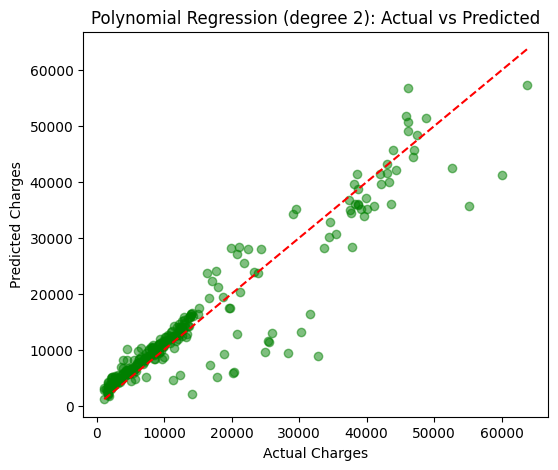

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_poly, alpha=0.5, color="green")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Polynomial Regression (degree 2): Actual vs Predicted")
plt.show()

## 8. Model comparison


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial (degree 2)"],
    "MSE": [mse_lin, mse_poly],
    "RMSE": [rmse_lin, rmse_poly],
    "MAE": [mae_lin, mae_poly],
    "R2": [r2_lin, r2_poly],
})
print(comparison)

                   Model           MSE         RMSE          MAE        R2
0      Linear Regression  3.547802e+07  5956.342894  4177.045561  0.806929
1  Polynomial (degree 2)  2.158584e+07  4646.056793  2867.317439  0.882530


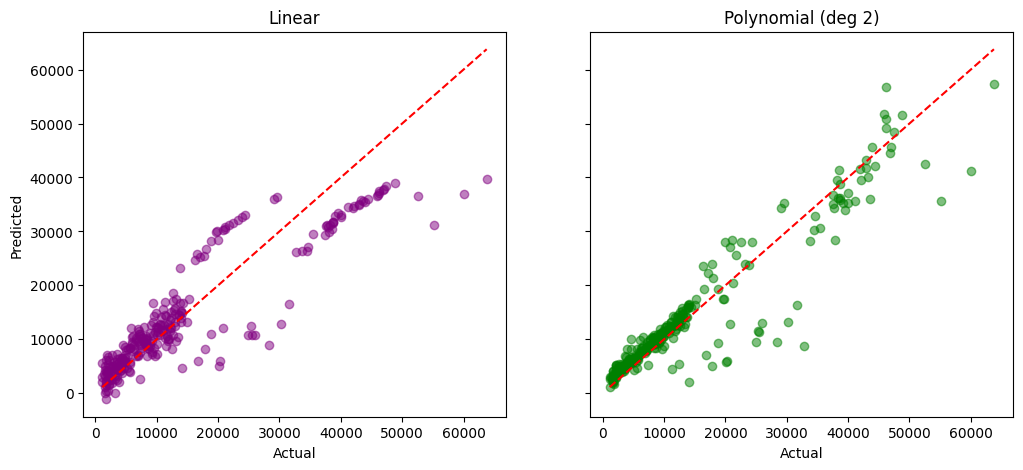

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for a, pred, title, c in zip(
    ax,
    [y_pred_lin, y_pred_poly],
    ["Linear", "Polynomial (deg 2)"],
    ["purple", "green"],
):
    a.scatter(y_test, pred, alpha=0.5, color=c)
    a.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    a.set_title(title)
    a.set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
plt.show()

## Conclusion
Polynomial Regression (degree 2) outperformed the linear baseline on all reported metrics. Higher degrees (3–4) lower the test score while training R² keeps rising, indicating overfitting. Limitations: single train/test split, degree chosen using test results, and only two model types compared.